# 04 · Strategy comparison
Strategies A-E, single-signal portfolios, alternative weightings, segments, variants and walk-forward weights.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
P = ROOT / 'data' / 'processed'; T = ROOT / 'outputs' / 'tables'

In [2]:
perf = pd.read_csv(T/'strategy_performance.csv')
perf[perf.benchmark=='Nifty 500'][['strategy','CAGR','bench_CAGR','excess_CAGR','excess_CAGR_ci_lo','excess_CAGR_ci_hi','t_excess_nw','sharpe','max_dd','avg_turnover_m']].round(3)

,strategy,CAGR,bench_CAGR,excess_CAGR,excess_CAGR_ci_lo,excess_CAGR_ci_hi,t_excess_nw,sharpe,max_dd,avg_turnover_m
0,A_block,0.107,0.12,-0.013,-0.090,0.081,0.016,0.310,-0.462,0.474
2,B_shareholding,0.157,0.12,0.037,-0.061,0.153,0.994,0.488,-0.466,0.306
4,C_inst_earnings,0.214,0.12,0.094,-0.014,0.221,2.057,0.673,-0.439,0.418
6,D_inst_block_earnings,0.185,0.12,0.065,-0.022,0.164,1.594,0.597,-0.402,0.438
8,E_full,0.203,0.12,0.083,0.016,0.160,2.334,0.765,-0.331,0.400
...,...,...,...,...,...,...,...,...,...,...
140,B_shareholding|valuation_filter,0.137,0.12,0.017,-0.059,0.119,0.669,0.424,-0.463,0.340
142,C_inst_earnings|valuation_filter,0.184,0.12,0.064,-0.019,0.170,1.834,0.590,-0.397,0.425
144,E_walk_forward,0.249,0.13,0.119,-0.013,0.271,1.927,0.889,-0.245,0.545
146,E_full(2021+),0.266,0.13,0.136,0.066,0.218,3.266,1.170,-0.197,0.384


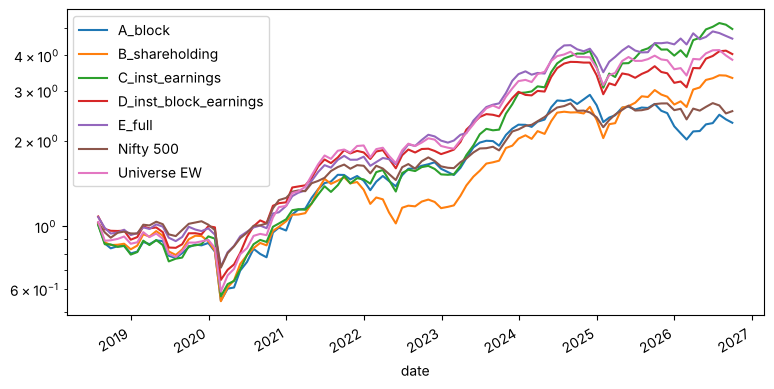

In [3]:
m = pd.read_csv(T/'monthly_returns_net.csv', index_col=0, parse_dates=True)
(1+m[['A_block','B_shareholding','C_inst_earnings','D_inst_block_earnings','E_full','Nifty 500','Universe EW']].fillna(0)).cumprod().plot(logy=True, figsize=(9,4.5)); plt.show()

In [4]:
pd.read_csv(T/'subperiod_performance.csv').round(3)

,strategy,period,months,CAGR,N500_CAGR,excess_vs_N500,t_excess_vs_N500,UEW_CAGR,excess_vs_UEW,t_excess_vs_UEW,sharpe,max_dd
0,A_block,development 2018-07..2021-12,42,0.111,0.151,-0.039,-0.189,0.206,-0.095,-1.940,0.317,-0.462
1,A_block,validation 2022-01..2023-12,24,0.256,0.159,0.097,1.581,0.298,-0.043,-0.587,1.080,-0.098
2,A_block,out-of-sample 2024-01..2026-10,33,0.006,0.055,-0.050,-0.523,0.065,-0.059,-0.871,-0.206,-0.304
3,A_block,full,99,0.107,0.120,-0.013,0.016,0.178,-0.071,-1.940,0.310,-0.462
4,B_shareholding,development 2018-07..2021-12,42,0.088,0.151,-0.062,-0.501,0.206,-0.118,-1.936,0.249,-0.466
5,B_shareholding,validation 2022-01..2023-12,24,0.230,0.159,0.072,0.738,0.298,-0.068,-0.855,0.804,-0.190
6,B_shareholding,out-of-sample 2024-01..2026-10,33,0.196,0.055,0.141,1.884,0.065,0.131,3.099,0.673,-0.224
7,B_shareholding,full,99,0.157,0.120,0.037,0.994,0.178,-0.021,-0.392,0.488,-0.466
8,C_inst_earnings,development 2018-07..2021-12,42,0.115,0.151,-0.036,-0.092,0.206,-0.091,-1.268,0.340,-0.439
9,C_inst_earnings,validation 2022-01..2023-12,24,0.419,0.159,0.261,2.505,0.298,0.121,1.685,1.421,-0.160


In [5]:
pd.read_csv(T/'regime_performance.csv').round(4)

,strategy,regime,months,mean_excess_m,t_nw,hit_rate,strategy_mean_m,bench_mean_m
0,A_block,bull (trailing 6m N500 >= 0),68,0.0002,0.0526,0.4706,0.0015,0.0013
1,A_block,bear (trailing 6m N500 < 0),31,-0.0003,-0.0627,0.4516,0.0316,0.0319
2,A_block,up month (N500 >= 0),65,-0.0003,-0.0755,0.4462,0.0380,0.0384
3,A_block,down month (N500 < 0),34,0.0008,0.1213,0.5000,-0.0409,-0.0416
4,B_shareholding,bull (trailing 6m N500 >= 0),68,0.0028,0.6007,0.4853,0.0041,0.0013
5,B_shareholding,bear (trailing 6m N500 < 0),31,0.0066,0.9543,0.5161,0.0385,0.0319
6,B_shareholding,up month (N500 >= 0),65,0.0074,1.9733,0.5077,0.0457,0.0384
7,B_shareholding,down month (N500 < 0),34,-0.0023,-0.2760,0.4706,-0.0440,-0.0416
8,C_inst_earnings,bull (trailing 6m N500 >= 0),68,0.0090,1.9973,0.6176,0.0102,0.0013
9,C_inst_earnings,bear (trailing 6m N500 < 0),31,0.0071,1.0248,0.6129,0.0390,0.0319


In [6]:
pd.read_csv(T/'concentration_extreme_winners.csv').round(3)

,strategy,sum_monthly_contrib,top5_share_of_sum,top10_share_of_sum,n_names_held,CAGR_net,CAGR_ex_top1,excess_ex_top1_vs_N500,CAGR_ex_top5,excess_ex_top5_vs_N500,CAGR_ex_top10,excess_ex_top10_vs_N500,CAGR_winsor99
0,A_block,1.602,0.142,0.256,433,0.107,0.101,-0.019,0.079,-0.041,0.057,-0.063,0.095
1,B_shareholding,1.800,0.147,0.258,367,0.157,0.151,0.031,0.124,0.004,0.099,-0.021,0.143
2,C_inst_earnings,2.351,0.118,0.210,473,0.214,0.206,0.086,0.177,0.057,0.149,0.029,0.199
3,D_inst_block_earnings,2.120,0.126,0.232,461,0.185,0.176,0.056,0.149,0.029,0.121,0.001,0.170
4,E_full,2.061,0.135,0.235,330,0.203,0.193,0.073,0.165,0.045,0.138,0.018,0.190


In [7]:
pd.read_csv(T/'walk_forward_weights.csv')

,year,train_start,train_end,n_train_months,w_earnings,w_institutional,w_quality,w_valuation,w_price_volume,train_obj_bp,base_train_obj_bp
0,2021,2018-07-31,2020-10-30,28,30.0,30.0,0.0,0.0,40.0,214.376520,21.476050
1,2022,2018-07-31,2021-10-29,40,0.0,30.0,0.0,0.0,70.0,175.288563,0.969970
2,2023,2018-07-31,2022-10-31,52,0.0,0.0,0.0,20.0,80.0,190.610985,36.093316
3,2024,2018-07-31,2023-10-31,64,0.0,20.0,0.0,0.0,80.0,175.993185,35.265614
4,2025,2018-07-31,2024-10-31,76,40.0,0.0,0.0,0.0,60.0,185.071179,43.697795
5,2026,2018-07-31,2025-10-31,88,40.0,0.0,0.0,0.0,60.0,150.652141,54.558181
